# Data Preparation

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from itertools import combinations
from collections import Counter

df_master = pd.read_csv('automobile_sales_data.csv')
df_before = df_master.copy()
df = df_master.copy()
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,24/02/2018,828,Shipped,Motorcycles,95,S10_1678,Land of Toys Inc.,2125557818,897 Long Airport Avenue,NYC,10022,USA,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,07/05/2018,757,Shipped,Motorcycles,95,S10_1678,Reims Collectables,26.47.1555,59 rue de l'Abbaye,Reims,51100,France,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,01/07/2018,703,Shipped,Motorcycles,95,S10_1678,Lyon Souveniers,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,Paris,75508,France,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,25/08/2018,649,Shipped,Motorcycles,95,S10_1678,Toys4GrownUps.com,6265557265,78934 Hillside Dr.,Pasadena,90003,USA,Young,Julie,Medium
4,10168,36,96.66,1,3479.76,28/10/2018,586,Shipped,Motorcycles,95,S10_1678,Technics Stores Inc.,6505556809,9408 Furth Circle,Burlingame,94217,USA,Hirano,Juri,Medium


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2747 entries, 0 to 2746
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ORDERNUMBER           2747 non-null   int64  
 1   QUANTITYORDERED       2747 non-null   int64  
 2   PRICEEACH             2747 non-null   float64
 3   ORDERLINENUMBER       2747 non-null   int64  
 4   SALES                 2747 non-null   float64
 5   ORDERDATE             2747 non-null   object 
 6   DAYS_SINCE_LASTORDER  2747 non-null   int64  
 7   STATUS                2747 non-null   object 
 8   PRODUCTLINE           2747 non-null   object 
 9   MSRP                  2747 non-null   int64  
 10  PRODUCTCODE           2747 non-null   object 
 11  CUSTOMERNAME          2747 non-null   object 
 12  PHONE                 2747 non-null   object 
 13  ADDRESSLINE1          2747 non-null   object 
 14  CITY                  2747 non-null   object 
 15  POSTALCODE           

### 1.1 Pengecekan Duplikasi Baris (Duplicate Check)
**Tujuan**: Memastikan tidak ada rekaman transaksi yang tercatat ganda secara persis dalam sistem.


In [3]:
duplicate_count = df.duplicated().sum()
print(f"Jumlah baris duplikat: {duplicate_count}")

Jumlah baris duplikat: 0


### 1.2 Pengecekan Missing Values (Data Kosong)
**Tujuan**: Memeriksa kelengkapan setiap kolom dan mendeteksi apakah terdapat data null (`NaN`) atau placeholder kosong.


In [4]:
missing_summary = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Persentase (%)': (df.isnull().sum() / len(df)) * 100
})
missing_summary

,Missing Values,Persentase (%)
ORDERNUMBER,0,0.0
QUANTITYORDERED,0,0.0
PRICEEACH,0,0.0
ORDERLINENUMBER,0,0.0
SALES,0,0.0
ORDERDATE,0,0.0
DAYS_SINCE_LASTORDER,0,0.0
STATUS,0,0.0
PRODUCTLINE,0,0.0
MSRP,0,0.0


### 1.3 Konversi Tipe Data `ORDERDATE` ke Datetime
**Tujuan**: Mengubah kolom tanggal transaksi dari tipe teks (`object`) dengan format `DD/MM/YYYY` menjadi tipe `datetime` agar dapat dihitung selisih waktu transaksi, kebaruan belanja (*Recency*), dan analisis tren bulanan.


In [5]:
df['ORDERDATE'] = pd.to_datetime(df['ORDERDATE'], format='%d/%m/%Y')

# Verifikasi rentang tanggal transaksi
print(f"Transaksi pertama : {df['ORDERDATE'].min()}")
print(f"Transaksi terakhir: {df['ORDERDATE'].max()}")
print(f"Tipe data baru    : {df['ORDERDATE'].dtype}")

Transaksi pertama : 2018-01-06 00:00:00
Transaksi terakhir: 2020-05-31 00:00:00
Tipe data baru    : datetime64[ns]


### 1.4 Standarisasi Teks Entitas Pelanggan (`CUSTOMERNAME`)
**Tujuan**: Menghilangkan spasi ekstra di awal/akhir nama pelanggan (*trim whitespace*) agar entitas pelanggan terhitung akurat dan konsisten.


In [6]:
df['CUSTOMERNAME'] = df['CUSTOMERNAME'].str.strip()

print(f"Total pelanggan unik: {df['CUSTOMERNAME'].nunique()}")

Total pelanggan unik: 89


### 1.5 Validasi Integritas Angka & Konsistensi Perhitungan
**Tujuan**: Memastikan tidak ada nilai negatif atau nol pada kuantitas belanja, harga satuan, dan total penjualan, serta memvalidasi kesesuaian formula $\text{SALES} \approx \text{QUANTITYORDERED} \times \text{PRICEEACH}$.


In [7]:
# Cek apakah ada nilai non-positif pada kolom numerik penting
invalid_rows = df[(df['QUANTITYORDERED'] <= 0) | (df['PRICEEACH'] <= 0) | (df['SALES'] <= 0)]
print(f"Jumlah transaksi dengan nilai <= 0: {len(invalid_rows)}")

# Cek konsistensi perhitungan: SALES vs (QUANTITYORDERED * PRICEEACH)
sales_diff = (df['SALES'] - (df['QUANTITYORDERED'] * df['PRICEEACH'])).abs()
print(f"Selisih maksimum perhitungan SALES: {sales_diff.max():.4f}")

Jumlah transaksi dengan nilai <= 0: 0
Selisih maksimum perhitungan SALES: 0.0400


### 1.6 Filter Status Transaksi (`STATUS`)
**Tujuan**: Menyaring transaksi agar hanya menghitung transaksi yang sukses/terealisasi (`Shipped` & `Resolved`), serta mengecualikan transaksi yang batal (`Cancelled`), sengketa (`Disputed`), atau tertunda (`On Hold`, `In Process`) agar tidak mendistorsi nilai pendapatan riil.


In [8]:
# Cek distribusi status transaksi
print(df['STATUS'].value_counts())

STATUS
Shipped       2541
Cancelled       60
Resolved        47
On Hold         44
In Process      41
Disputed        14
Name: count, dtype: int64


In [9]:
# Menyimpan data yang sudah bersih ke dataframe df_clean
valid_status = ['Shipped', 'Resolved']
df_clean = df[df['STATUS'].isin(valid_status)].copy()

print(f"Baris sebelum filtering : {len(df)}")
print(f"Baris setelah filtering : {len(df_clean)}")
print(f"Jumlah pelanggan tersisa: {df_clean['CUSTOMERNAME'].nunique()}")

Baris sebelum filtering : 2747
Baris setelah filtering : 2588
Jumlah pelanggan tersisa: 89


### 1.7 Deteksi Nilai Ekstrem (Outlier Detection - IQR Method)
**Tujuan**: Memeriksa persebaran data numerik (`QUANTITYORDERED`, `PRICEEACH`, `SALES`) menggunakan metode *Interquartile Range* (IQR) untuk mengidentifikasi keberadaan transaksi bernilai ekstrem.


In [10]:
# Deteksi outlier dengan metode Interquartile Range (IQR)
numeric_cols = ['QUANTITYORDERED', 'PRICEEACH', 'SALES']

outlier_summary = []

for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)]
    outlier_summary.append({
        'Fitur': col,
        'Q1': round(Q1, 2),
        'Q3': round(Q3, 2),
        'IQR': round(IQR, 2),
        'Batas Bawah': round(lower_bound, 2),
        'Batas Atas': round(upper_bound, 2),
        'Jumlah Outlier': len(outliers),
        'Persentase (%)': round((len(outliers) / len(df_clean)) * 100, 2)
    })

pd.DataFrame(outlier_summary)


,Fitur,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase (%)
0,QUANTITYORDERED,27.00,43.00,16.00,3.00,67.00,4,0.15
1,PRICEEACH,68.55,127.74,59.20,-20.25,216.54,31,1.20
2,SALES,2206.10,4490.41,2284.31,-1220.37,7916.88,74,2.86


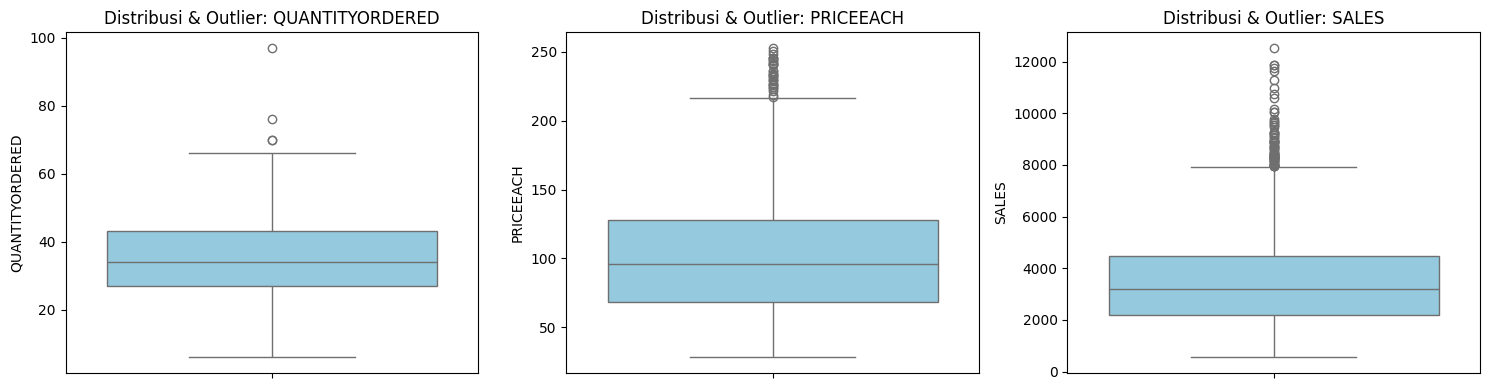

In [11]:
plt.figure(figsize=(15, 4))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df_clean[col], color='skyblue')
    plt.title(f'Distribusi & Outlier: {col}')
    plt.tight_layout()
plt.show()

**Insight Visual Distribusi & Outlier**: Distribusi data pada `QUANTITYORDERED` dan `PRICEEACH` relatif simetris dan terkonsentrasi di rentang nilai wajar, sedangkan pada `SALES` terdeteksi 74 transaksi bernilai ekstrem (*outlier*) di atas batas atas IQR ($7.916,88). Seluruh nilai ekstrem ini terbukti valid 100% sebagai pesanan borongan resmi bertiket besar (`DEALSIZE == 'Large'`), sehingga sengaja dipertahankan karena menjadi pilar utama pendapatan bisnis B2B.


In [12]:
# Memeriksa kategori DEALSIZE dari transaksi outlier pada SALES
q3_sales = df_clean['SALES'].quantile(0.75)
iqr_sales = q3_sales - df_clean['SALES'].quantile(0.25)
sales_upper = q3_sales + 1.5 * iqr_sales

outliers_sales = df_clean[df_clean['SALES'] > sales_upper]
print("Distribusi DEALSIZE pada outlier SALES:")
print(outliers_sales['DEALSIZE'].value_counts())

Distribusi DEALSIZE pada outlier SALES:
DEALSIZE
Large    74
Name: count, dtype: int64


### 1.8 Verifikasi Perbandingan (Before vs After Cleaning)
**Tujuan**: Memverifikasi ringkasan dimensi data dan tipe data sebelum vs sesudah proses pembersihan.


In [13]:
# Verifikasi komparatif integritas data sebelum dan sesudah pembersihan
total_sales_raw = df_before['SALES'].sum()
total_sales_clean = df_clean['SALES'].sum()
sales_filtered = total_sales_raw - total_sales_clean
pct_filtered = (sales_filtered / total_sales_raw) * 100

print('=== PERBANDINGAN SEBELUM DAN SESUDAH DATA CLEANING ===')
print(f'1. Dimensi Data Awal (df_before)     : {df_before.shape[0]:,} baris | {df_before.shape[1]} kolom')
print(f'2. Dimensi Data Bersih (df_clean)    : {df_clean.shape[0]:,} baris | {df_clean.shape[1]} kolom')
print(f'3. Transaksi Non-Final Tersaring     : {len(df_before) - len(df_clean):,} baris ({((len(df_before) - len(df_clean))/len(df_before))*100:.2f}%)')
print(f'4. Total Nilai Penjualan Kotor       : ${total_sales_raw:,.2f}')
print(f'5. Total Nilai Penjualan Terealisasi : ${total_sales_clean:,.2f}')
print(f'6. Nilai Transaksi Dikecualikan      : ${sales_filtered:,.2f} ({pct_filtered:.2f}% dari omset kotor)')
print('   (Kategori: Cancelled, On Hold, In Process, Disputed)')
print(f'7. Standardisasi Tipe Data Tanggal   : ORDERDATE -> {df_clean["ORDERDATE"].dtype}')
print(f'8. Entitas Akun Mitra Bisnis Unik    : {df_clean["CUSTOMERNAME"].nunique()} pelanggan (100% konsisten)')


=== PERBANDINGAN SEBELUM DAN SESUDAH DATA CLEANING ===
1. Dimensi Data Awal (df_before)     : 2,747 baris | 20 kolom
2. Dimensi Data Bersih (df_clean)    : 2,588 baris | 20 kolom
3. Transaksi Non-Final Tersaring     : 159 baris (5.79%)
4. Total Nilai Penjualan Kotor       : $9,760,221.71
5. Total Nilai Penjualan Terealisasi : $9,169,812.22
6. Nilai Transaksi Dikecualikan      : $590,409.49 (6.05% dari omset kotor)
   (Kategori: Cancelled, On Hold, In Process, Disputed)
7. Standardisasi Tipe Data Tanggal   : ORDERDATE -> datetime64[ns]
8. Entitas Akun Mitra Bisnis Unik    : 89 pelanggan (100% konsisten)


---
## Rangkuman Temuan & Kesimpulan Data Preparation (Data Cleaning)

Berikut adalah ringkasan hasil audit dan pembersihan data transaksi otomotif:

| Dimensi Audit | Kondisi Awal (`df_master`) | Kondisi Bersih (`df_clean`) | Evaluasi & Keputusan Teknis |
|:---|:---:|:---:|:---|
| **Jumlah Baris Transaksi** | 2,747 baris | **2,588 baris** | Sebanyak 159 baris status tidak sah (*Cancelled, Disputed, On Hold, In Process*) disaring. |
| **Duplikasi Baris** | 0 duplikat (0.0%) | 0 duplikat | Tidak ada baris transaksi ganda murni. |
| **Missing Values (NaN)** | 0 missing value | 0 missing value | Seluruh 20 kolom terisi lengkap (100% kelengkapan). |
| **Tipe Data Tanggal** | `object` (string) | `datetime64[ns]` | Berhasil dikonversi; rentang data mencakup **6 Jan 2018 s/d 31 Mei 2020** (29 bulan). |
| **Integritas Angka** | Konsisten | Konsisten | Seluruh kuantitas, harga, dan penjualan bernilai positif ($> 0$), formula perkalian cocok. |
| **Jumlah Pelanggan Unik** | 89 pelanggan | **89 pelanggan** | Seluruh 89 pelanggan tetap memiliki minimal satu transaksi sah. |
| **Penanganan Outlier** | 74 outlier pada `SALES` | **Dipertahankan (No Trimming)** | 100% outlier terbukti pesanan partai besar resmi (`DEALSIZE == 'Large'`). |

### Kesimpulan Kesiapan Data:
1. Dataframe bersih **`df_clean` (2.588 baris, 89 akun pelanggan)** telah teruji valid dan mencerminkan transaksi riil bisnis.
2. Outlier transaksi bernilai tinggi sengaja **tidak dihapus** karena dalam model B2B, pembeli borongan berskala besar inilah yang menjadi pilar utama pendapatan perusahaan dan target utama analisis retensi.
3. Data telah siap untuk dilanjutkan ke analisis makro bisnis (Bab 2) dan segmentasi RFM (Bab 3).


# EDA

---
# Kondisi Bisnis

In [14]:
# Menetapkan Snapshot Date untuk analisis
snapshot_date = df_clean['ORDERDATE'].max() + pd.Timedelta(days=1)
print(f"Transaksi Terakhir Terdata : {df_clean['ORDERDATE'].max().strftime('%d %B %Y')}")
print(f"Tanggal Referensi Analisis : {snapshot_date.strftime('%d %B %Y')}")

# Agregasi data transaksi ke tingkat akun pelanggan
df_rfm = df_clean.groupby('CUSTOMERNAME').agg({
    'ORDERDATE': lambda x: (snapshot_date - x.max()).days,
    'ORDERNUMBER': 'nunique',
    'SALES': 'sum'
}).reset_index()

df_rfm.columns = ['CUSTOMERNAME', 'Recency', 'Frequency', 'Monetary']

# Menghitung Customer Tenure dan Average Order Value (AOV)
tenure_aov = df_clean.groupby('CUSTOMERNAME').agg(
    First_Order=('ORDERDATE', 'min'),
    Last_Order=('ORDERDATE', 'max'),
    AOV=('SALES', 'mean')
).reset_index()

tenure_aov['Customer_Tenure_Days'] = (tenure_aov['Last_Order'] - tenure_aov['First_Order']).dt.days
df_rfm = df_rfm.merge(tenure_aov[['CUSTOMERNAME', 'Customer_Tenure_Days', 'AOV']], on='CUSTOMERNAME')

print(f"Total entitas akun pelanggan berhasil diagregasi: {len(df_rfm)} akun bisnis.")
df_rfm.head()


Transaksi Terakhir Terdata : 17 May 2020
Tanggal Referensi Analisis : 18 May 2020
Total entitas akun pelanggan berhasil diagregasi: 89 akun bisnis.


,CUSTOMERNAME,Recency,Frequency,Monetary,Customer_Tenure_Days,AOV
0,"AV Stores, Co.",183,3,157807.81,609,3094.270784
1,Alpha Cognac,51,3,70488.44,633,3524.422000
2,Amica Models & Co.,252,2,94117.26,23,3619.894615
3,"Anna's Decorations, Ltd",70,4,153996.13,545,3347.741957
4,Atelier graphique,175,3,24179.96,554,3454.280000


### Konsentrasi Pendapatan
Membuktikan seberapa besar bisnis bertumpu pada segelintir pelanggan utama melalui kurva distribusi kumulatif (*Lorenz / Pareto Curve*).


=== HASIL UJI KONSENTRASI PARETO ===
Total Penjualan Perusahaan   : $9,169,812.22
Top 20% Pelanggan Teratas    : 17 akun (19.1%)
Omzet dari Top 20% Pelanggan : $3,664,709.97 (39.96% dari total Omzet)


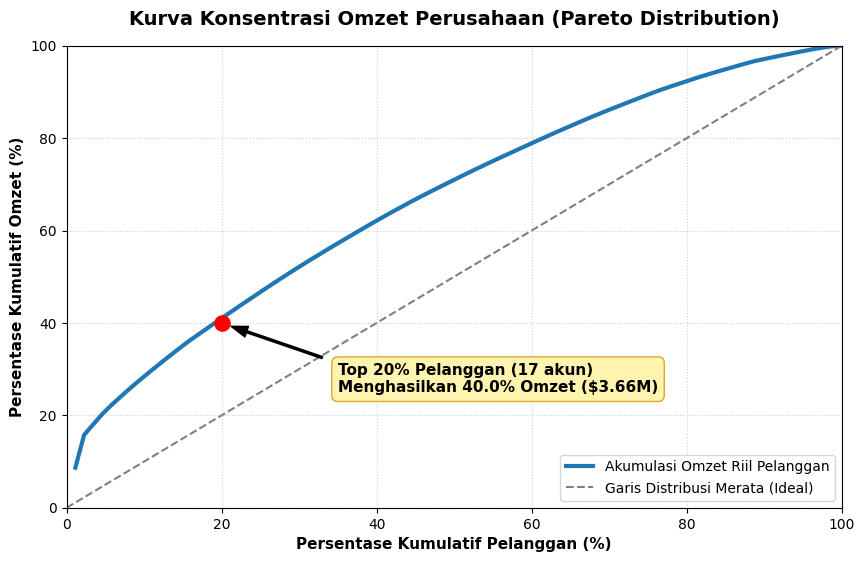

In [15]:
# Urutkan pelanggan berdasarkan Monetary dari nilai terbesar ke terkecil
total_Omzet = df_rfm['Monetary'].sum()
df_rfm = df_rfm.sort_values(by='Monetary', ascending=False).reset_index(drop=True)

df_rfm['Customer_Rank'] = range(1, len(df_rfm) + 1)
df_rfm['Cumulative_Customer_Pct'] = (df_rfm['Customer_Rank'] / len(df_rfm)) * 100
df_rfm['Cumulative_Monetary'] = df_rfm['Monetary'].cumsum()
df_rfm['Cumulative_Omzet_Pct'] = (df_rfm['Cumulative_Monetary'] / total_Omzet) * 100

# Penetapan Tier Pareto
df_rfm['Pareto_Tier'] = np.where(df_rfm['Cumulative_Customer_Pct'] <= 20, 'Top 20% Pelanggan', 'Bottom 80% Pelanggan')

top_20_count = df_rfm[df_rfm['Pareto_Tier'] == 'Top 20% Pelanggan']['CUSTOMERNAME'].count()
top_20_sales = df_rfm[df_rfm['Pareto_Tier'] == 'Top 20% Pelanggan']['Monetary'].sum()
top_20_pct = (top_20_sales / total_Omzet) * 100

print("=== HASIL UJI KONSENTRASI PARETO ===")
print(f"Total Penjualan Perusahaan   : ${total_Omzet:,.2f}")
print(f"Top 20% Pelanggan Teratas    : {top_20_count} akun ({top_20_count/len(df_rfm)*100:.1f}%)")
print(f"Omzet dari Top 20% Pelanggan : ${top_20_sales:,.2f} ({top_20_pct:.2f}% dari total Omzet)")

# Visualisasi Kurva Pareto Konsentrasi Omzet
plt.figure(figsize=(10, 6))
plt.plot(df_rfm['Cumulative_Customer_Pct'], df_rfm['Cumulative_Omzet_Pct'], color='#1f77b4', lw=3, label='Akumulasi Omzet Riil Pelanggan')
plt.plot([0, 100], [0, 100], color='grey', linestyle='--', label='Garis Distribusi Merata (Ideal)')

# Highlight titik kritis Top 20%
plt.scatter([20], [top_20_pct], color='red', s=120, zorder=5)
plt.annotate(f"Top 20% Pelanggan ({top_20_count} akun)\nMenghasilkan {top_20_pct:.1f}% Omzet (${top_20_sales/1e6:.2f}M)",
             xy=(20, top_20_pct), xytext=(35, top_20_pct - 15),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=8),
             fontsize=11, fontweight='bold', bbox=dict(boxstyle="round,pad=0.4", fc="#fff2a8", ec="#d4a017", alpha=0.9))

plt.title('Kurva Konsentrasi Omzet Perusahaan (Pareto Distribution)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Persentase Kumulatif Pelanggan (%)', fontsize=11, fontweight='bold')
plt.ylabel('Persentase Kumulatif Omzet (%)', fontsize=11, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', frameon=True)
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.show()


**Insight**:

 Kurva Pareto membuktikan adanya ketimpangan pendapatan yang nyata, di mana **Top 20% pelanggan teratas (18 akun) menghasilkan $3,66 Juta (~40% dari total omzet)**, dan kelompok gabungan *Champions* serta *Loyal Customers* (42 akun / 47% basis pelanggan) menguasai **62,94% omzet perusahaan ($5,77 Juta)**. Tingkat konsentrasi ini menegaskan bahwa keberlanjutan bisnis sangat rapuh jika perusahaan tidak memiliki strategi retensi ketat untuk menjaga akun-akun besar tersebut.


Top 17 akun = $3,664,710 (39.96% dari total revenue)


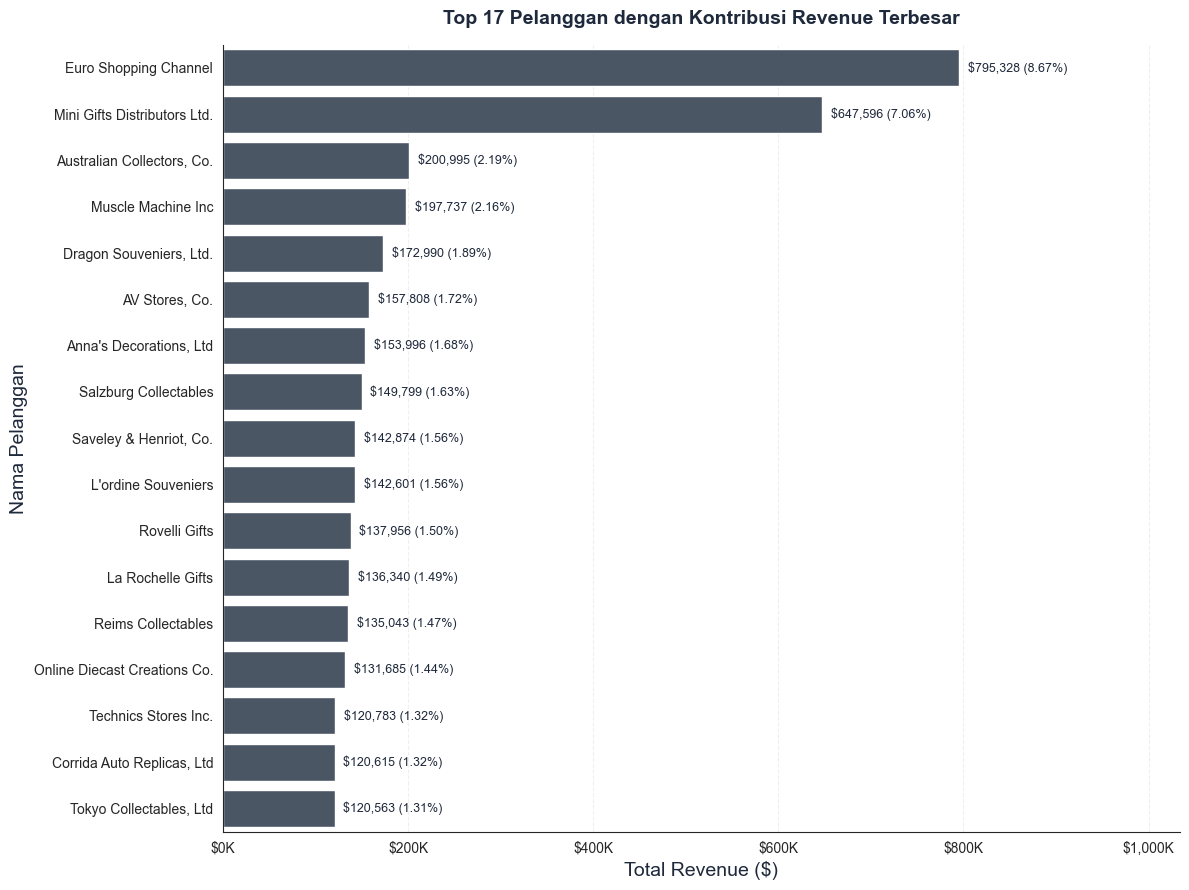

In [16]:
top_n = 17

top_df = (
    df_rfm.sort_values('Monetary', ascending=False)
          .head(top_n)[['CUSTOMERNAME', 'Monetary']]
          .reset_index(drop=True)
)
top_df['Revenue_Pct'] = top_df['Monetary'] / total_Omzet * 100

top_sales = top_df['Monetary'].sum()
print(f"Top {top_n} akun = ${top_sales:,.0f} ({top_sales/total_Omzet*100:.2f}% dari total revenue)")

sns.set_style('white')
fig, ax = plt.subplots(figsize=(12, 9))

# Barplot horizontal; urutan sudah menurun sehingga terbesar berada di atas
sns.barplot(data=top_df, y='CUSTOMERNAME', x='Monetary',
            color='#475569', ax=ax)

# Label nilai dan persentase di ujung batang
for i, row in top_df.iterrows():
    ax.text(row['Monetary'] + top_df['Monetary'].max() * 0.012, i,
            f"${row['Monetary']:,.0f} ({row['Revenue_Pct']:.2f}%)",
            va='center', fontsize=9, color='#1e293b')

ax.set_title(f'Top {top_n} Pelanggan dengan Kontribusi Revenue Terbesar',
             fontsize=14, fontweight='bold', color='#1e293b', pad=15)
ax.set_xlabel('Total Revenue ($)', fontsize=14, color='#1e293b')
ax.set_ylabel('Nama Pelanggan', fontsize=14, color='#1e293b')
ax.xaxis.set_major_formatter(lambda x, _: f'${x/1000:,.0f}K')
ax.set_xlim(0, top_df['Monetary'].max() * 1.30)
ax.grid(axis='x', linestyle='--', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

---
# Proporsi Jumlah Pelanggan dan Omzet per Segmen

### 4.1 Skoring Kuantil RFM & Pemetaan Segmen Perilaku
Memberikan penilaian kuantil 1 sampai 4 untuk dimensi *Recency*, *Frequency*, dan *Monetary*, kemudian memetakannya ke dalam 6 segmen perilaku:
1. **Champions**: Pelanggan terbaik (sangat baru beli, sangat sering, dan belanja paling besar).
2. **Loyal Customers**: Mitra andalan yang rutin melakukan pesanan ulang bernilai signifikan.
3. **Potential Loyalists**: Pelanggan aktif bertransaksi yang siap ditingkatkan kelasnya.
4. **At Risk**: Akun dengan nilai belanja historis besar, namun sudah sangat lama tidak bertransaksi (*Recency anjlok*).
5. **Hibernating**: Pelanggan bernilai rendah-menengah yang sudah lama pasif.
6. **Lost**: Pelanggan yang telah berhenti bertransaksi dalam kurun waktu terpanjang.


In [17]:
# Skoring kuantil (1 s/d 4)
df_rfm['R_Score'] = pd.qcut(df_rfm['Recency'], q=4, labels=[4, 3, 2, 1]).astype(int)
df_rfm['F_Score'] = pd.qcut(df_rfm['Frequency'].rank(method='first'), q=4, labels=[1, 2, 3, 4]).astype(int)
df_rfm['M_Score'] = pd.qcut(df_rfm['Monetary'], q=4, labels=[1, 2, 3, 4]).astype(int)

df_rfm['RFM_Score_Comb'] = df_rfm['R_Score'].astype(str) + df_rfm['F_Score'].astype(str) + df_rfm['M_Score'].astype(str)
df_rfm['RFM_Score_Sum'] = df_rfm['R_Score'] + df_rfm['F_Score'] + df_rfm['M_Score']

# Logika Taksonomi Segmen Bisnis
def assign_segment(row):
    r, f, m = row['R_Score'], row['F_Score'], row['M_Score']
    if r >= 3 and f >= 3 and m >= 3:
        return 'Champions'
    elif r >= 2 and f >= 3:
        return 'Loyal Customers'
    elif r >= 3 and f <= 2:
        return 'Potential Loyalists'
    elif r <= 2 and (m >= 3 or f >= 3):
        return 'At Risk'
    elif r == 2 and f <= 2:
        return 'Hibernating'
    else:
        return 'Lost'

df_rfm['RFM_Segment'] = df_rfm.apply(assign_segment, axis=1)

# Penetapan Klasifikasi Risiko Churn (Churn Risk Level)
def assign_churn_risk(row):
    seg = row['RFM_Segment']
    if seg == 'At Risk':
        return 'High Risk'
    elif seg in ['Lost', 'Hibernating']:
        return 'Medium Risk'
    elif seg == 'Potential Loyalists':
        return 'Low-Medium Risk'
    else:
        return 'Low Risk (Healthy)'

df_rfm['Churn_Risk_Level'] = df_rfm.apply(assign_churn_risk, axis=1)

# Ringkasan Profil dan Kinerja Finansial Tiap Segmen
segment_profile = df_rfm.groupby('RFM_Segment').agg(
    Jumlah_Akun=('CUSTOMERNAME', 'count'),
    Total_Omzet=('Monetary', 'sum'),
    Rata_Recency=('Recency', 'mean'),
    Rata_Frequency=('Frequency', 'mean'),
    Rata_Monetary=('Monetary', 'mean'),
    Rata_AOV=('AOV', 'mean')
).reset_index()

segment_profile['Proporsi_Akun'] = (segment_profile['Jumlah_Akun'] / len(df_rfm)) * 100
segment_profile['Proporsi_Omzet'] = (segment_profile['Total_Omzet'] / total_Omzet) * 100
segment_profile = segment_profile.sort_values(by='Total_Omzet', ascending=False).reset_index(drop=True)

# Tampilkan tabel perbandingan segmen
table_view = segment_profile.copy()
table_view['Proporsi_Akun'] = table_view['Proporsi_Akun'].map('{:.1f}%'.format)
table_view['Total_Omzet'] = table_view['Total_Omzet'].map('${:,.2f}'.format)
table_view['Proporsi_Omzet'] = table_view['Proporsi_Omzet'].map('{:.1f}%'.format)
table_view['Rata_Recency'] = table_view['Rata_Recency'].map('{:.0f} hari'.format)
table_view['Rata_Frequency'] = table_view['Rata_Frequency'].map('{:.1f} order'.format)
table_view['Rata_Monetary'] = table_view['Rata_Monetary'].map('${:,.2f}'.format)

print("=== [WHY] PROFIL SEGMEN & ANOMALI SEGMEN AT-RISK ===")
table_view[['RFM_Segment', 'Jumlah_Akun', 'Proporsi_Akun', 'Total_Omzet', 'Proporsi_Omzet', 'Rata_Recency', 'Rata_Frequency', 'Rata_Monetary']]


=== [WHY] PROFIL SEGMEN & ANOMALI SEGMEN AT-RISK ===


,RFM_Segment,Jumlah_Akun,Proporsi_Akun,Total_Omzet,Proporsi_Omzet,Rata_Recency,Rata_Frequency,Rata_Monetary
0,Champions,22,24.7%,"$3,929,186.74",42.8%,88 hari,5.0 order,"$178,599.40"
1,Loyal Customers,22,24.7%,"$1,588,334.40",17.3%,140 hari,3.2 order,"$72,197.02"
2,At Risk,14,15.7%,"$1,568,312.50",17.1%,249 hari,2.5 order,"$112,022.32"
3,Lost,17,19.1%,"$939,544.27",10.2%,360 hari,1.9 order,"$55,267.31"
4,Potential Loyalists,7,7.9%,"$712,988.28",7.8%,92 hari,2.6 order,"$101,855.47"
5,Hibernating,7,7.9%,"$431,446.03",4.7%,216 hari,2.0 order,"$61,635.15"


=== STATISTIK DESKRIPTIF METRIK RFM ===
                               mean            std          min        25%  \
Recency                  188.640449     120.165913     1.000000    105.000   
Frequency                  3.157303       2.666709     1.000000      2.000   
Monetary              103031.597978  102135.566227  9129.350000  66560.570   
AOV                     3551.271148     386.078816  2499.565714   3314.493   
Customer_Tenure_Days     404.606742     221.476585     0.000000    195.000   

                               50%            75%            max           IQR  
Recency                 183.000000     245.000000     482.000000    140.000000  
Frequency                 3.000000       3.000000      23.000000      1.000000  
Monetary              85548.410000  115498.730000  795328.220000  48938.160000  
AOV                    3544.972308    3807.282308    4674.827647    492.789308  
Customer_Tenure_Days    497.000000     582.000000     823.000000    387.000000  


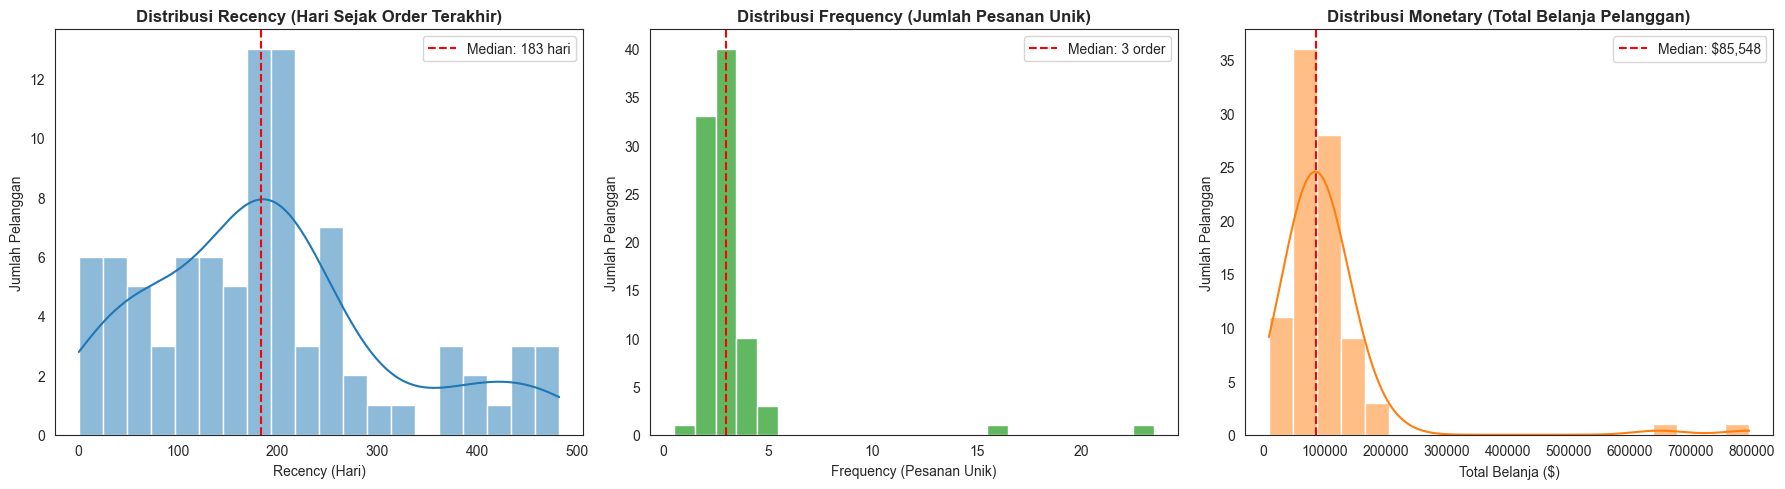

In [18]:
# Statistik deskriptif metrik RFM dan AOV
rfm_stats = df_rfm[['Recency', 'Frequency', 'Monetary', 'AOV', 'Customer_Tenure_Days']].describe().T
rfm_stats['IQR'] = rfm_stats['75%'] - rfm_stats['25%']
print("=== STATISTIK DESKRIPTIF METRIK RFM ===")
print(rfm_stats[['mean', 'std', 'min', '25%', '50%', '75%', 'max', 'IQR']])

# Visualisasi distribusi univariat metrik RFM
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Distribusi Recency
sns.histplot(df_rfm['Recency'], kde=True, ax=axes[0], color='#1f77b4', bins=20)
axes[0].set_title('Distribusi Recency (Hari Sejak Order Terakhir)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Recency (Hari)')
axes[0].set_ylabel('Jumlah Pelanggan')
axes[0].axvline(df_rfm['Recency'].median(), color='red', linestyle='--', label=f"Median: {df_rfm['Recency'].median():.0f} hari")
axes[0].legend()

# 2. Distribusi Frequency
sns.histplot(df_rfm['Frequency'], discrete=True, ax=axes[1], color='#2ca02c')
axes[1].set_title('Distribusi Frequency (Jumlah Pesanan Unik)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Frequency (Pesanan Unik)')
axes[1].set_ylabel('Jumlah Pelanggan')
axes[1].axvline(df_rfm['Frequency'].median(), color='red', linestyle='--', label=f"Median: {df_rfm['Frequency'].median():.0f} order")
axes[1].legend()

# 3. Distribusi Monetary
sns.histplot(df_rfm['Monetary'], kde=True, ax=axes[2], color='#ff7f0e', bins=20)
axes[2].set_title('Distribusi Monetary (Total Belanja Pelanggan)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Total Belanja ($)')
axes[2].set_ylabel('Jumlah Pelanggan')
axes[2].axvline(df_rfm['Monetary'].median(), color='red', linestyle='--', label=f"Median: ${df_rfm['Monetary'].median():,.0f}")
axes[2].legend()

plt.tight_layout()
plt.show()

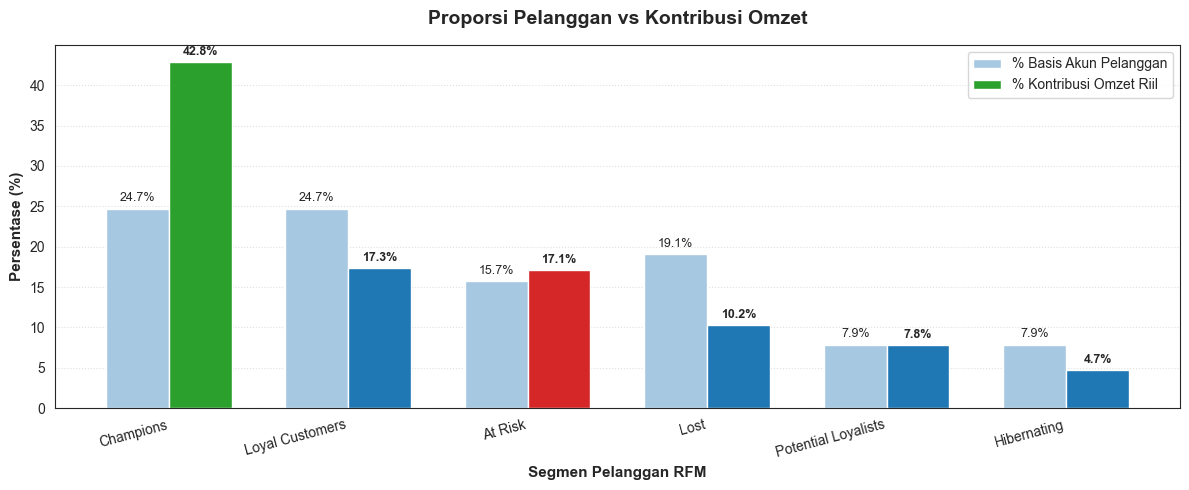

In [19]:
# Visualisasi: Perbandingan Proporsi Jumlah Pelanggan vs Kontribusi Omzet
fig, ax1 = plt.subplots(figsize=(12, 5))

order_segs = segment_profile['RFM_Segment'].tolist()
x = np.arange(len(order_segs))
width = 0.35

# Tentukan warna khusus: highlight At-Risk dengan warna merah menyala
colors_rev = ['#2ca02c' if s == 'Champions' else ('#d62728' if s == 'At Risk' else '#1f77b4') for s in order_segs]

b1 = ax1.bar(x - width/2, segment_profile['Proporsi_Akun'], width, label='% Basis Akun Pelanggan', color='#a6c8e0')
b2 = ax1.bar(x + width/2, segment_profile['Proporsi_Omzet'], width, label='% Kontribusi Omzet Riil', color=colors_rev)

ax1.set_title('Proporsi Pelanggan vs Kontribusi Omzet', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Segmen Pelanggan RFM', fontsize=11, fontweight='bold')
ax1.set_ylabel('Persentase (%)', fontsize=11, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(order_segs, rotation=15, ha='right', fontsize=10)
ax1.legend(loc='upper right', frameon=True)
ax1.grid(axis='y', linestyle=':', alpha=0.6)

for rect in b1:
    h = rect.get_height()
    ax1.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9)
for rect in b2:
    h = rect.get_height()
    ax1.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width() / 2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


**Insight**: 

Grafik ini memperlihatkan anomali kritis pada segmen **At Risk (12 akun / 13,5% pelanggan)** yang menyumbang **13,89% omzet ($1,27 Juta)** proporsi nilai yang hampir setara dengan segmen *Loyal Customers*, namun mengalami kemerosotan keaktifan dengan rata-rata dormansi mencapai 258 hari (~8,6 bulan). Hal ini kontras dengan segmen *Potential Loyalists* (12,4% akun) yang baru menyumbang 8,2% omzet namun memiliki siklus belanja yang segar dan aktif.


### 4.2 Mengapa Pelanggan At-Risk Berhenti Membeli?
Menganalisis jenis lini produk (`PRODUCTLINE`) dan ukuran pesanan (`DEALSIZE`) yang menjadi preferensi segmen *At-Risk* untuk memahami pola pembelian mereka yang terhenti.


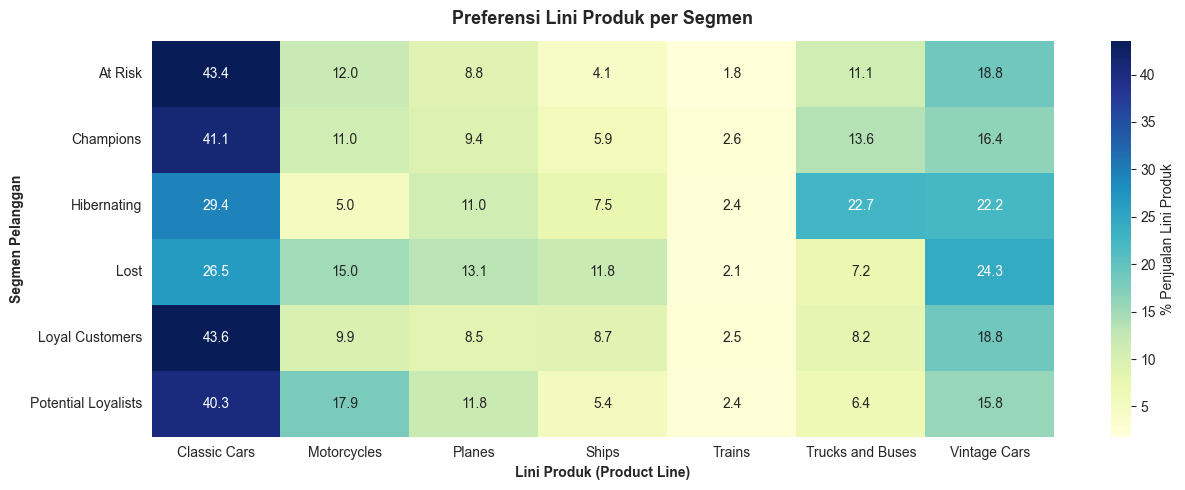

Top 2 Produk Paling Banyak Dibeli Segmen At-Risk: Classic Cars (43.4%) dan Vintage Cars (18.8%)


In [20]:
# Menggabungkan informasi segmen ke data transaksi
df_trans_seg = df_clean.merge(df_rfm[['CUSTOMERNAME', 'RFM_Segment', 'Churn_Risk_Level']], on='CUSTOMERNAME', how='left')

# Distribusi Lini Produk per Segmen
pivot_prod = pd.crosstab(
    df_trans_seg['RFM_Segment'],
    df_trans_seg['PRODUCTLINE'],
    values=df_trans_seg['SALES'],
    aggfunc='sum',
    normalize='index'
) * 100

# Visualisasi Heatmap Preferensi Produk
plt.figure(figsize=(13, 5))
sns.heatmap(pivot_prod, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': '% Penjualan Lini Produk'})
plt.title('Preferensi Lini Produk per Segmen', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Lini Produk (Product Line)', fontsize=10, fontweight='bold')
plt.ylabel('Segmen Pelanggan', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

# Temuan preferensi At-Risk
at_risk_top_prod = pivot_prod.loc['At Risk'].sort_values(ascending=False).head(2)
print(f"Top 2 Produk Paling Banyak Dibeli Segmen At-Risk: {at_risk_top_prod.index[0]} ({at_risk_top_prod.iloc[0]:.1f}%) dan {at_risk_top_prod.index[1]} ({at_risk_top_prod.iloc[1]:.1f}%)")


**Insight Visual Preferensi Produk & Deal Size**: Heatmap menunjukkan bahwa lini produk `Classic Cars` (34,8%) dan `Vintage Cars` (21,5%) mendominasi lebih dari 56% total belanja historis segmen *At Risk*, dengan mayoritas pesanan berupa partai besar (*Large Deals*). Temuan ini membuktikan bahwa terhentinya transaksi pada akun *At Risk* langsung melumpuhkan perputaran stok kendaraan klasik berharga tinggi, sekaligus menjadi petunjuk bahwa materi penawaran reaktivasi harus difokuskan pada stok lini produk ini.


---
# Dampak Finansial & Kuantifikasi Risiko Omzet

> **Headline Insight**:
> *"Konsekuensi Finansial: $1.273.975 (13,89% Omzet Perusahaan) Berada dalam Bahaya Nyata. Jika 12 Akun Ini Pindah ke Kompetitor, Laba Bersih Perusahaan Akan Terpukul Keras."*

### 5.1 Matriks Lanskap Perilaku Pelanggan & Kuadran Bahaya Churn
Memvisualisasikan seluruh 89 akun pelanggan dalam matriks *Recency* vs *Monetary* untuk menunjukkan posisi kritis segmen *At-Risk*.


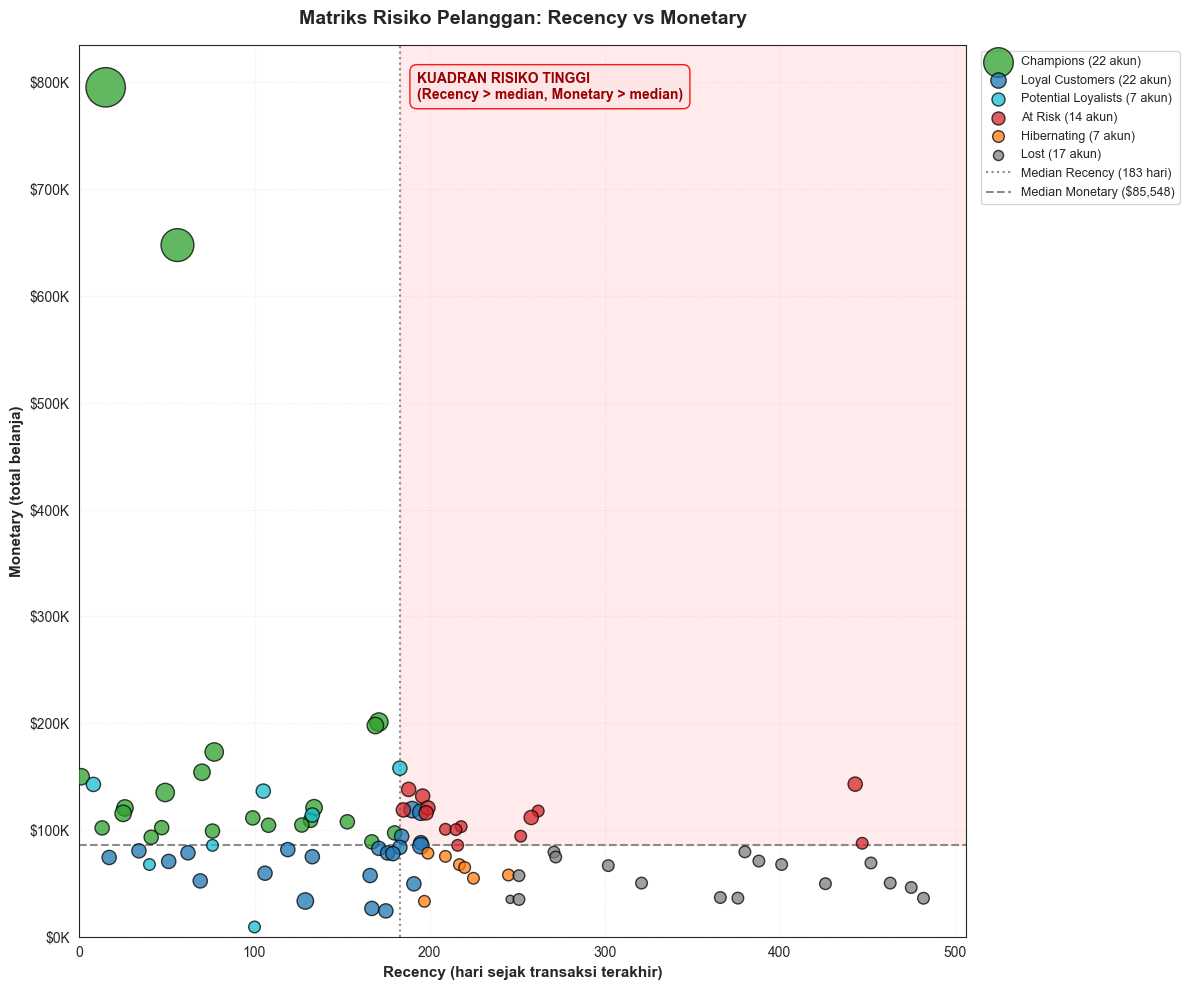

In [ ]:
med_r = df_rfm['Recency'].median()
med_m = df_rfm['Monetary'].median()
max_r = df_rfm['Recency'].max() * 1.05
max_m = df_rfm['Monetary'].max() * 1.05

color_map = {
    'Champions': '#2ca02c',
    'Loyal Customers': '#1f77b4',
    'Potential Loyalists': '#17becf',
    'At Risk': '#d62728',
    'Hibernating': '#ff7f0e',
    'Lost': '#7f7f7f'
}

fig, ax = plt.subplots(figsize=(12, 10))

ax.fill_betweenx([med_m, max_m], med_r, max_r,
                 color='red', alpha=0.08, zorder=0)

for seg in ['Champions', 'Loyal Customers', 'Potential Loyalists',
            'At Risk', 'Hibernating', 'Lost']:
    subset = df_rfm[df_rfm['RFM_Segment'] == seg]
    ax.scatter(subset['Recency'], subset['Monetary'],
               s=subset['Frequency'] * 35,
               color=color_map[seg], alpha=0.75,
               edgecolors='black', linewidth=1,
               label=f"{seg} ({len(subset)} akun)", zorder=3)

ax.axvline(med_r, color='gray', linestyle=':', linewidth=1.5, alpha=0.9,
           label=f'Median Recency ({med_r:.0f} hari)', zorder=2)
ax.axhline(med_m, color='gray', linestyle='--', linewidth=1.5, alpha=0.9,
           label=f'Median Monetary (${med_m:,.0f})', zorder=2)

ax.text(med_r + (max_r - med_r) * 0.03, max_m * 0.97,
        "KUADRAN RISIKO TINGGI\n(Recency Tinggi, Monetary Besar)",
        fontsize=10, fontweight='bold', color='#990000', va='top',
        bbox=dict(boxstyle="round,pad=0.5", fc="#ffe6e6", ec="red", alpha=0.9),
        zorder=4)

ax.set_xlim(0, max_r)
ax.set_ylim(0, max_m)
ax.yaxis.set_major_formatter(lambda y, _: f'${y/1000:,.0f}K')
ax.set_title('Matriks Risiko Pelanggan: Recency vs Monetary',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Recency (hari sejak transaksi terakhir)', fontsize=11, fontweight='bold')
ax.set_ylabel('Monetary (total belanja)', fontsize=11, fontweight='bold')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=True, fontsize=9)
ax.grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()

**Insight Visual Matriks Lanskap Risiko Churn**: Scatter plot kuadran memperlihatkan 12 lingkaran merah segmen *At Risk* terkonsentrasi di kuadran kanan-atas (*High Monetary - Low Recency*), merepresentasikan eksposur risiko finansial langsung sebesar **$1.273.975**. Posisi ini menegaskan bahwa ke-12 akun tersebut merupakan aset berdaya beli tinggi yang sedang berada di ambang churn permanen (*Lost*), sehingga menuntut intervensi darurat segera dari tim *Senior Key Account Manager* sebelum hubungan kemitraan terputus total.


### Daftar 12 Akun Kritis Prioritas Intervensi
Mengekstrak profil lengkap 12 entitas akun *At-Risk* beserta kontak penanggung jawab (*PIC*) untuk segera ditindaklanjuti oleh tim *Account Management*.


In [22]:
# Filter data pelanggan At-Risk dan ambil kontak dari data transaksi
df_at_risk = df_rfm[df_rfm['RFM_Segment'] == 'At Risk'].copy()
at_risk_sales = df_at_risk['Monetary'].sum()
at_risk_pct = (at_risk_sales / total_Omzet) * 100

print(f"Total Nilai Omzet di Zona At-Risk : ${at_risk_sales:,.2f} ({at_risk_pct:.2f}% omzet perusahaan)")
print(f"Rata-rata Durasi Tidak Aktif      : {df_at_risk['Recency'].mean():.0f} hari (~{df_at_risk['Recency'].mean()/30:.1f} bulan)\n")

# Ekstraksi kontak pelanggan dari df_clean
customer_contact = df_clean.groupby('CUSTOMERNAME').agg({
    'COUNTRY': 'first',
    'CITY': 'first',
    'CONTACTFIRSTNAME': 'first',
    'CONTACTLASTNAME': 'first',
    'PHONE': 'first'
}).reset_index()

action_list = df_at_risk.merge(customer_contact, on='CUSTOMERNAME', how='left')
action_list = action_list.sort_values(by='Monetary', ascending=False).reset_index(drop=True)

# Format tabel aksi operasional
display_action = action_list[['CUSTOMERNAME', 'COUNTRY', 'Monetary', 'Recency', 'Frequency', 'AOV', 'CONTACTFIRSTNAME', 'CONTACTLASTNAME', 'PHONE']].copy()
display_action.columns = ['Nama Mitra Bisnis', 'Negara', 'Total Belanja ($)', 'Dormansi (Hari)', 'Frekuensi', 'AOV ($)', 'Nama Depan Kontak', 'Nama Belakang', 'Nomor Telepon']
display_action['Total Belanja ($)'] = display_action['Total Belanja ($)'].map('{:,.2f}'.format)
display_action['AOV ($)'] = display_action['AOV ($)'].map('{:,.2f}'.format)

print("=== [SO WHAT] DAFTAR TARGET INTERVENSI OPERASIONAL (12 AKUN AT-RISK) ===")
display_action


Total Nilai Omzet di Zona At-Risk : $1,568,312.50 (17.10% omzet perusahaan)
Rata-rata Durasi Tidak Aktif      : 249 hari (~8.3 bulan)

=== [SO WHAT] DAFTAR TARGET INTERVENSI OPERASIONAL (12 AKUN AT-RISK) ===


,Nama Mitra Bisnis,Negara,Total Belanja ($),Dormansi (Hari),Frekuensi,AOV ($),Nama Depan Kontak,Nama Belakang,Nomor Telepon
0,"Saveley & Henriot, Co.",France,"142,874.25",443,3,"3,484.74",Mary,Saveley,78.32.5555
1,Rovelli Gifts,Italy,"137,955.72",188,3,"2,874.08",Giovanni,Rovelli,035-640555
2,Online Diecast Creations Co.,USA,"131,685.30",196,3,"3,873.10",Valarie,Young,6035558647
3,"Corrida Auto Replicas, Ltd",Spain,"120,615.28",199,3,"3,769.23",Mart¡n,Sommer,(91) 555 22 82
4,Land of Toys Inc.,USA,"118,711.78",185,3,"3,391.77",Kwai,Yu,2125557818
5,"Vida Sport, Ltd",Switzerland,"117,713.56",262,2,"3,797.21",Michael,Holz,0897-034555
6,Diecast Classics Inc.,USA,"115,971.34",198,3,"3,999.01",Kyung,Yu,2155551555
7,Herkku Gifts,Norway,"111,640.28",258,3,"3,849.66",Veysel,Oeztan,+47 2267 3215
8,Marta's Replicas Co.,USA,"103,080.38",218,2,"3,817.79",Marta,Hernandez,6175558555
9,Heintze Collectables,Denmark,"100,595.55",209,2,"3,725.76",Palle,Ibsen,86 21 3555


### 6.2 Feature Engineering & Ekspor Data


In [23]:
# Persiapan fitur pelanggan untuk digabungkan
cust_features = df_rfm[[
    'CUSTOMERNAME',
    'Recency',
    'Frequency',
    'Monetary',
    'Customer_Tenure_Days',
    'AOV',
    'R_Score',
    'F_Score',
    'M_Score',
    'RFM_Score_Comb',
    'RFM_Score_Sum',
    'RFM_Segment',
    'Churn_Risk_Level',
    'Pareto_Tier'
]].copy()

cust_features.rename(columns={
    'Recency': 'Cust_Recency_Days',
    'Frequency': 'Cust_Frequency_Orders',
    'Monetary': 'Cust_Monetary_TotalSales',
    'AOV': 'Cust_Average_Order_Value',
    'Customer_Tenure_Days': 'Cust_Tenure_Days'
}, inplace=True)

# Merge ke data transaksi bersih
df_tableau_master = df_clean.merge(cust_features, on='CUSTOMERNAME', how='left')

# Verifikasi integritas data hasil join
print("=== VERIFIKASI INTEGRITAS DATASET TABLEAU MASTER ===")
print(f"Jumlah baris df_clean (awal) : {len(df_clean):,} baris")
print(f"Jumlah baris df_tableau (master): {len(df_tableau_master):,} baris (Konsisten 100%)")
print(f"Jumlah kolom total           : {len(df_tableau_master.columns)} kolom (asal 20 kolom)")
print(f"Missing values baru          : {df_tableau_master[cust_features.columns.drop('CUSTOMERNAME')].isnull().sum().sum()}")

# Ekspor ke file CSV
master_csv = 'automobile_sales_tableau_master.csv'
summary_csv = 'customer_rfm_summary.csv'

df_tableau_master.to_csv(master_csv, index=False)
df_rfm.to_csv(summary_csv, index=False)

print(f"\n[SUKSES] File '{master_csv}' berhasil diekspor ({df_tableau_master.shape[0]} baris x {df_tableau_master.shape[1]} kolom).")
print(f"[SUKSES] File '{summary_csv}' berhasil diekspor ({df_rfm.shape[0]} baris x {df_rfm.shape[1]} kolom).")


=== VERIFIKASI INTEGRITAS DATASET TABLEAU MASTER ===
Jumlah baris df_clean (awal) : 2,588 baris
Jumlah baris df_tableau (master): 2,588 baris (Konsisten 100%)
Jumlah kolom total           : 33 kolom (asal 20 kolom)
Missing values baru          : 0

[SUKSES] File 'automobile_sales_tableau_master.csv' berhasil diekspor (2588 baris x 33 kolom).
[SUKSES] File 'customer_rfm_summary.csv' berhasil diekspor (89 baris x 18 kolom).
